 # Ensambles paralelos homogeneos

Los métodos de conjunto paralelo entrenan cada estimador base independientemente de los demás, lo que significan que se pueden entrenar en paralelo. Dependiendo del conjunto de modelos base que utilicen se puede distinguir entre ensambles homogeneos y heterogeneos. Empezaremos revisando modelos homogenoes como lo son baggin y random forest.

Dados que los dos elementos esenciales de los modelos de ensamble son la diversidad y la agregación del modelo, enensambles homogeneos la diversidad se logra a través de random sampling (bagging), características o ambos, como lo hacen los random forest.

## Bagging: Bootstrap aggregating

Bagging, abreviación de bootstrap aggregating, fue introducido por Leo Breiman en 1996, y su nombre viene de la forma cómo se logra la diversidad del ensamble, a través del botstrap sampling o muestreo con remplazo, para luego hacer una agregación de los modelos.

El Bagging consiste en dos pasos: primero se realiza el muestreo con remplazo de subconjuntos del conjunto original dedatos, después se combinan para tener una unica predicción del ensamble.

Entonces, partimnos por generar los subconjuntos del conjunto original de entrnamiento, el cual se hace a terravés de remuestreo con remplazo, que es lo que se conoce como Bootstrap sampling. Naturalmente, esto genera dos subconjuntos:
1. Boostrap sample
2. Out-of-bag (OOB) sample: las que no estan en el subconjunto muestreado.

Podemos, entonces, entrenar diferentes estimadores base o modelos con cada bootstrap. Estos modelos se pueden evaluar internamente con el OOB, estimando un error de predicción que generalmente se conoce como error OOB o puntuación OOB. El error OOB promedio es una buena estimación del desempeño del conjunto general.

Utilicemos numpy para generar muestras con remplazo. Tomemos un conjunto de 50 observaciones, podemos generar bootstrap sample del mismo tamaño como sigue:

In [1]:
# bootstrap sample

import numpy as np

bag = np.random.choice(range(0,50),size=50,replace=True)
np.sort(bag)

array([ 0,  1,  4,  5,  8, 10, 10, 12, 13, 14, 15, 15, 16, 17, 19, 19, 20,
       21, 22, 23, 23, 24, 25, 28, 28, 29, 31, 31, 31, 32, 32, 35, 37, 38,
       38, 39, 39, 40, 42, 42, 43, 43, 43, 44, 44, 46, 46, 46, 47, 49])

In [2]:
# OOB sample

oob = np.setdiff1d(range(0,50),bag)
oob

array([ 2,  3,  6,  7,  9, 11, 18, 26, 27, 30, 33, 34, 36, 41, 45, 48])

Nótese que el muestreo bootstrap contendrá aproximadamente el 63.2% del conjunto de datos, mientras que la muestra OOB contendrá el 36.8%. Esto se deduce del hecho de quemientras la probabilidad de elegir un registro es de $\frac{1}{n}$, la probabilidad de que sea parte delconjunto será de $1-\frac{1}{n}$, por lo que para $n$ puntos, tenemos que la probabilidad global de ser elegido:
$$
(1-\frac{1}{n})^{n} \approx e^{-1} \approx 0.368
$$

## Model agrregation

Habiendo entrenado diversos modelos independientes, debemos agregarlos en un estimador final, lo ual se puede hacerpot majority voting o moda estadística (en tareas de clasificación) o averaging (para tareas de regresión). De alguna manera, si los estimadores base son sólidos, la agregación funcionara como una suavización de los erroes de los estimadores base.



In [3]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

# Inicializamos una semilla para reproducibilidad

rng = np.random.RandomState(seed=4190)

# La función aceptará parámetros como número de estimadores (árboles)
# profundidad y muestras de entrenamiento

def bagging_fit(X, y, n_estimators, max_depth = 5, max_samples = 200):
  n_samples = len(y) # observaciones disponibles n

  # Creamos una lista de estimadores base no entrenados
  estimators = [DecisionTreeClassifier(max_depth = max_depth) for _ in range(n_estimators)]

  # ahora, por cada elemento de la lista, muestreamo y entrenamos
  for tree in estimators:
    # Generamos un bootstrap sample (selección de los índices de las muestras)
    bag = rng.choice(n_samples, max_samples, replace = True)
    # Entrenamos cada arbol
    tree.fit(X[bag,:],y[bag])

  return estimators

In [4]:
# Usaremos la moda como método de agregación

from scipy.stats import mode

# obtenemos las predicciones individuales sobre X convirtiéndolas en un array

def bagging_predict(X, estimators):
  all_predictions = np.array([tree.predict(X) for tree in estimators])
  # Aplicamos la moda sobre el eje 0, es decir entre las filas
  # le pedimos además que no mantenga la dimensión original sino que nos de
  # solo elvalor de la mofa en forma unidimensional
  # se asignan dos objetos ya que uno es el valor otro la cuenta
  y_pred, _ = mode(all_predictions, axis = 0, keepdims = False)

  return y_pred

Recordemos que nuestros estimadores base puede ser estimadores debiles, pero los que nos interesa es que sus erroes no estén demasiado correlacionados, de tal maneraque al combinar sus predicciones podamos obtener un modelo robusto.

Probemos nuestra implementación en 2 dimensiones y visualicemos los resultados. Utilizaremos el accuaracy como métrica de evaluación, la cual mide el total de predicciones corrctas sobre el total de predicciones realizadas.

In [5]:
from sklearn.datasets import make_moons # datos sintéticos para clasificación
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # métrica de evaluación
import matplotlib.pyplot as plt

# Generamos los datos usando make moons el cual genera dos clases
# en forma de medias lunas entrelazadas

X, y = make_moons(n_samples= 300, noise= 0.25, random_state= rng)
X.shape # (300,2) son dos características
y.shape

# Dividimos nuestro conjunto de datos

Xtrn, Xtst, ytrn, ytst = train_test_split(X, y, test_size= 0.33, random_state= rng)

# Entrenamiento del ensamble

bag_ens = bagging_fit(Xtrn, ytrn, n_estimators= 500, max_depth= 12, max_samples = 300)

# Nótese que se usan 300 ejemplos sobre un set de entrenamiento de 201
# esto sólo es posible porque se trata de muestreo con remplazo

y_pred = bagging_predict(Xtst, bag_ens)

print(accuracy_score(ytst, y_pred))

0.898989898989899


Para la prueba visual veamos una comparación entre un único arbol frente a nuestro bagging

In [6]:
# entrenamiento de un arbol individual

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Entrenamos un árbol individual
tree = DecisionTreeClassifier(max_depth=12)
tree.fit(Xtrn, ytrn)

# Predicciones sobre el conjunto de prueba
y_pred_tree = tree.predict(Xtst)

# Accuracy de ambos modelos
acc_tree = accuracy_score(ytst, y_pred_tree)
acc_bag = accuracy_score(ytst, y_pred)

print(f"Single tree: {acc_tree:.2%}")
print(f"Bagging:     {acc_bag:.2%}")

Single tree: 84.85%
Bagging:     89.90%


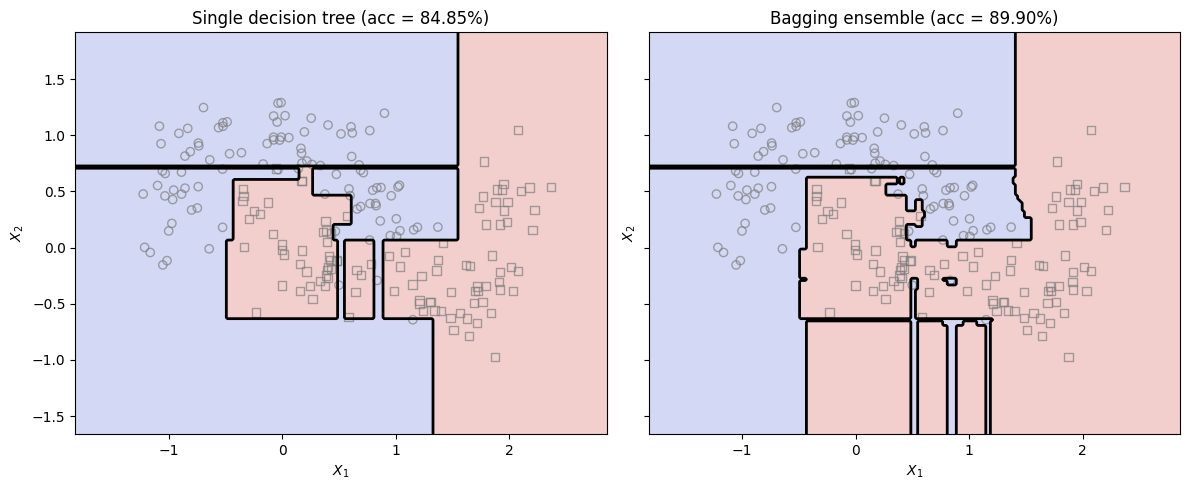

In [7]:
# Definimos los límites del plano
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# Creamos una malla de coordenadas
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Predicciones del árbol individual
Z_tree = tree.predict(grid)

# Predicciones del ensamble
Z_bag = bagging_predict(grid, bag_ens)

# Recuperamos las dimensiones originales
Z_tree = Z_tree.reshape(xx.shape)
Z_bag = Z_bag.reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

models = [
    (Z_tree, acc_tree, "Single decision tree"),
    (Z_bag, acc_bag, "Bagging ensemble")
]

for ax, (Z, acc, name) in zip(axes, models):

    # Representamos las regiones de clasificación
    ax.contourf(
        xx, yy, Z,
        alpha=0.25,
        cmap="coolwarm"
    )

    # Dibujamos la frontera de decisión
    ax.contour(
        xx, yy, Z,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    # Representamos las observaciones originales
    for cls, marker in [(0, "o"), (1, "s")]:
        ax.scatter(
            Xtrn[ytrn == cls, 0],
            Xtrn[ytrn == cls, 1],
            marker=marker,
            facecolors="none",
            edgecolors="gray",
            alpha=0.7
        )

    ax.set_title(f"{name} (acc = {acc:.2%})")
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")

plt.tight_layout()
plt.show()

## Bagging con scikit-learn

Probemo usar bagging para una tarea de clasificación utilizando las herramientas de scikit-learrn, el cual también ofrece soporte para paralelización, la capacidad de utilizar otros algoritmos de aprendizaje base mas allá de los arboles de decisión yu evaluación OOB.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

# Instanciamos el estimador base

base_estimator = DecisionTreeClassifier(max_depth=10)

# Instanciamos el bagging

bag_ens = BaggingClassifier(
     estimator = base_estimator,
     n_estimators=500,
     max_samples=100, # cada estimador será entrenado con muestras de 100
     oob_score = True, # usamos OOB para estimar la generalización
     random_state = rng
)

# Ajustamos el ensemble a los datos

bag_ens.fit(Xtrn, ytrn)

# Predecimos con los datos de prueba

ypred = bag_ens.predict(Xtst)

print(f"OOB score: {bag_ens.oob_score_:.2%}") # puntuación OOB

print(f"Accuracy: {accuracy_score(ytst, ypred):.2%}")


OOB score: 94.03%
Accuracy: 92.93%


Bagging es más eficaz con clasificadores complejos y no lineales que tienden a sobreajustar los datos. Estos modelos complejos y sobreajustados son inestables, es decir, muy sensibles a pequeñas variaciones en los datos de entrenamiento. Para ver por qué, consideremos que los árboles de decisión individuales en un conjunto en bolsas tienen aproximadamente la misma complejidad. Sin embargo, debido al muestreo de arranque, fueron entrenados en diferentes réplicas del conjunto de datos y se sobreajustaron de manera diferente. Dicho de otra manera, todos se sobreadaptan aproximadamente en la misma cantidad, pero en diferentes lugares.